In [1]:
import os
import random

import wandb

api = wandb.Api()

wandb_project = 'learneddb/lcm'


def get_table_df(url: str, label: str):
    print(url)
    artifact = api.artifact(url)
    artifact.download()

    table = artifact.get(label)
    return table.get_dataframe()


if os.path.exists('wandb_df_cache.pkl'):
    import pickle

    with open('wandb_df_cache.pkl', 'rb') as f:
        df_cache = pickle.load(f)
else:
    df_cache = dict()


def get_dataframes_from_run(run: str):
    if run in df_cache:
        print(f'Found run {run} in cache')
        return df_cache[run]

    if wandb.run is None:
        wandb.init()

    df_dict = {}

    instance = api.run(f'{wandb_project}/{run}')

    for key in instance.summary.keys():
        if key.endswith('pred_table'):
            df_dict[key] = get_table_df(f'{wandb_project}/run-{run}-{key}:latest', key)

    df_cache[run] = df_dict

    # save cache to file
    import pickle
    with open('wandb_df_cache.pkl', 'wb') as f:
        pickle.dump(df_cache, f)

    return df_dict

In [31]:
runs = [
    # '8tn6ih3o',
    # 'vyuutioc',
    # 'ivqkjj6c',
    # 'o3vdkq0c',
    # '3w89oh35',
    '7wfuqhla'
]
run_dict = dict()
for run in runs:
    run_dict[run] = get_dataframes_from_run(run)

Found run 7wfuqhla in cache


In [32]:
run = runs[0]

df = run_dict[run]['join_order_job_eval_pred_table']
grouped_df = df.groupby('sql')

opt_runtimes = []
picked_runtimes = []
opt_plan_instances = []
picked_plan_instances = []

for sql, group in grouped_df:
    min_runtime = group['label'].min()

    # get the picked plan runtime (the one with the lowest prediction)
    picked_plan = group.loc[group['prediction'].idxmin()]
    picked_plan_runtime = picked_plan['label']

    opt_runtimes.append(min_runtime)
    opt_plan_instances.append(group.loc[group['label'].idxmin()])
    picked_runtimes.append(picked_plan_runtime)
    picked_plan_instances.append(picked_plan)

print(f'Optimal runtime: {sum(opt_runtimes)}')
print(f'Picked runtime: {sum(picked_runtimes)}')

Optimal runtime: 156.789198
Picked runtime: 307.52280799999994


## Plot JOB Speedup Overview

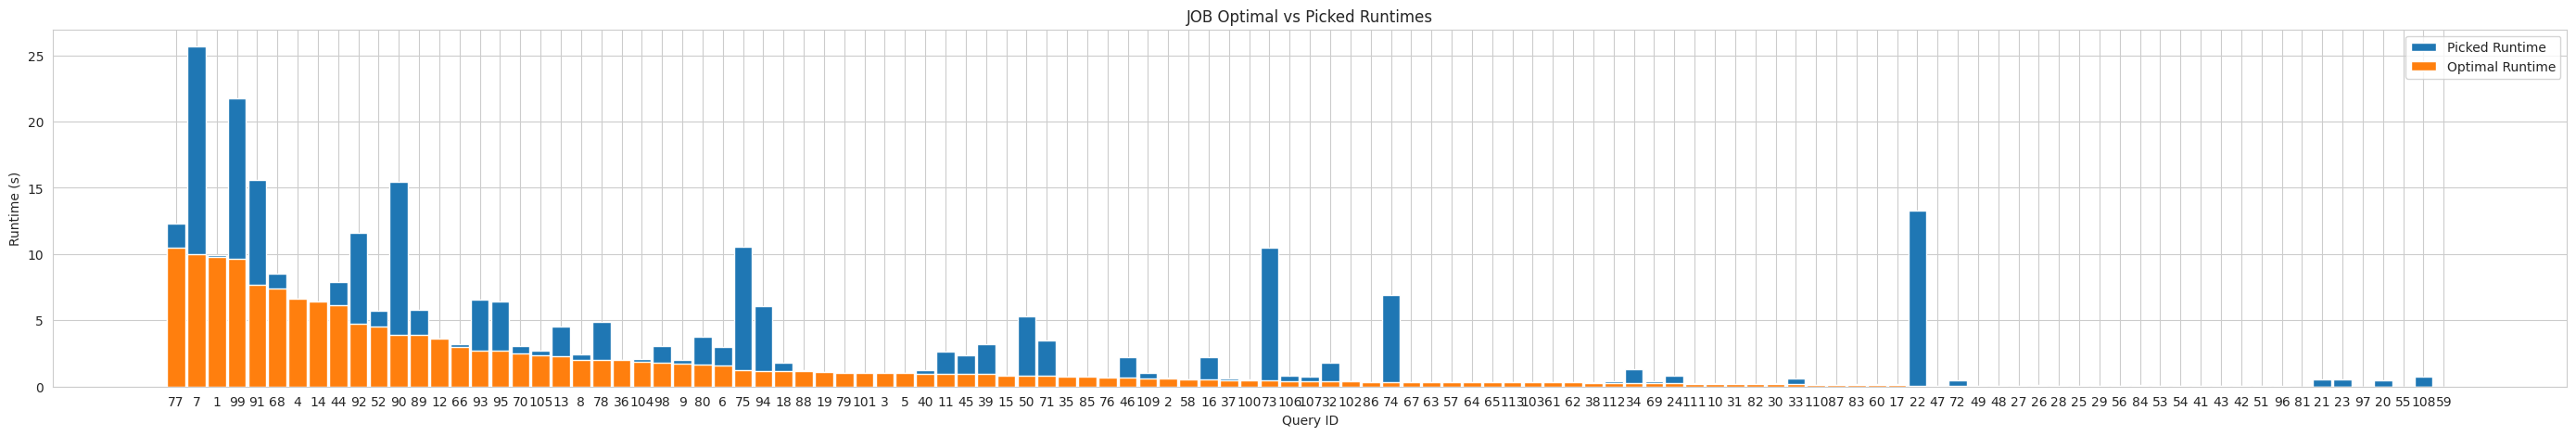

In [33]:
# plot barchart with selected runtime and optimal runtime for each query
import matplotlib.pyplot as plt

q_id = [i for i in range(len(opt_runtimes))]

# sort by opt runtime
sorted_indices = [i for i in sorted(range(len(opt_runtimes)), key=lambda k: opt_runtimes[k], reverse=True)]
opt_runtimes_sorted = [opt_runtimes[i] for i in sorted_indices]
picked_runtimes_sorted = [picked_runtimes[i] for i in sorted_indices]
q_id_sorted = [q_id[i] + 1 for i in sorted_indices]

plt.figure(figsize=(35, 5))
bar_width = 0.9
indices = range(len(opt_runtimes))
plt.bar(indices, picked_runtimes_sorted, width=bar_width, label='Picked Runtime')
plt.bar(indices, opt_runtimes_sorted, width=bar_width, label='Optimal Runtime')
plt.xticks([i for i in indices], q_id_sorted)
plt.legend()
plt.xlabel('Query ID')
plt.ylabel('Runtime (s)')
plt.title('JOB Optimal vs Picked Runtimes')
plt.show()

### Add to wandb run

In [34]:
print(f'Picked:')
print(picked_runtimes_sorted[:10])
print(f'Optimal:')
print(opt_runtimes_sorted[:10])

wandb_run = wandb.init(entity='learneddb', project='lcm', id=run, resume='must')
wandb_run.log(
    {
        "join_order_job_eval_plot": wandb.plot.line_series(
            xs=range(len(opt_runtimes)),
            ys=[opt_runtimes_sorted, picked_runtimes_sorted],
            keys=["Optimal Runtimes", "Picked Runtimes"],
            title="JOB - Picked vs. Optimal Runtimes",
            xname="Query ID",
        ),
    }
)


Picked:
[12.300222, 25.671302, 9.943767, 21.747441, 15.592872, 8.488288, 6.618164, 6.434912000000001, 7.899141999999999, 11.630336]
Optimal:
[10.500892, 10.00379, 9.778678, 9.633718, 7.671487, 7.3947650000000005, 6.618164, 6.434912000000001, 6.149793, 4.760705]


access_path_selection.json/epoch_test_loss,2657.20215
access_path_selection.json/epoch_test_mape,2624.79199
access_path_selection.json/epoch_test_median_q_error_100,672797.5
access_path_selection.json/epoch_test_median_q_error_50,8.07867
access_path_selection.json/epoch_test_median_q_error_95,64.24221
access_path_selection.json/epoch_test_mse,14.80197
access_path_selection.json/epoch_test_num_tuples,512
access_path_selection.json/epoch_test_spearman_rank,0.76589
access_path_selection.json/epoch_test_time,5.8588
access_path_selection.json/test_loss,13959.02539
access_path_selection.json/test_mape,263.04181


## Print Info about query with largest potential

In [6]:
from evaluation.analysis_helper import search_plan, create_explain_dalibo_entry
from tabulate import tabulate

# find idx with highest absolute error
absolute_slowdown = [picked - opt for picked, opt in zip(picked_runtimes, opt_runtimes)]
max_idx = absolute_slowdown.index(max(absolute_slowdown))

print(f'Max absolute slowdown: {absolute_slowdown[max_idx]:.2f}s ({max_idx})')

opt_p = opt_plan_instances[max_idx]
picked_p = picked_plan_instances[max_idx]

# find matching plan
opt_plans = search_plan(opt_p['sql'], opt_p['hint'])
picked_plans = search_plan(picked_p['sql'], picked_p['hint'])

assert len(opt_plans) == 1
assert len(picked_plans) == 1

# create dalibo entries
random_id = random.randint(0, 1000)

create_dalibo = False
if create_dalibo:
    opt_url = create_explain_dalibo_entry(opt_p['sql'], opt_plans[0]['analyze_plans'][0], f'{random_id}_Optimal')
    picked_url = create_explain_dalibo_entry(picked_p['sql'], picked_plans[0]['analyze_plans'][0],
                                             f'{random_id}_Picked')
else:
    opt_url = 'not created'
    picked_url = 'not created'

# print stuff
print(opt_p['sql'])
header = ['Val', 'Optimal', 'Picked']
tabulate_rows = [
    ['Runtime', opt_p['label'], picked_p['label']],
    ['Prediction', opt_p['prediction'], picked_p['prediction']],
    ['Absolute Slowdown', '-', absolute_slowdown[max_idx]],
    ['Relative Slowdown', '-', picked_p['label'] / opt_p['label']],
    ['Hint', opt_p['hint'][:20], picked_p['hint']][:20],
    ['Dalibo', opt_url, picked_url]
]
print(tabulate(tabulate_rows, headers=header))

Max absolute slowdown: 17.84s (6)
Loading job file imdb_scaled1/join_order_job_w_idxs_combined.json
SELECT MIN(an.name) AS cool_actor_pseudonym, MIN(t.title) AS series_named_after_char FROM aka_name AS an, cast_info AS ci, company_name AS cn, keyword AS k, movie_companies AS mc, movie_keyword AS mk, name AS n, title AS t WHERE cn.country_code ='[us]' AND k.keyword ='character-name-in-title' AND an.person_id = n.id AND n.id = ci.person_id AND ci.movie_id = t.id AND t.id = mk.movie_id AND mk.keyword_id = k.id AND t.id = mc.movie_id AND mc.company_id = cn.id AND an.person_id = ci.person_id AND ci.movie_id = mc.movie_id AND ci.movie_id = mk.movie_id AND mc.movie_id = mk.movie_id;
Val                Optimal               Picked
-----------------  --------------------  ----------------------------------
Runtime            10.003789901733398    27.842493057250977
Prediction         6.949408054351807     0.2255663275718689
Absolute Slowdown  -                     17.838703155517578
Relative Sl